#Effort, Sleep, and Risk
##Analysis of Student Exam Performance & Success Dataset
**Dataset is from synthetic data

## 3 Questions to Investigate from the Data:
Which students are overworking without payoff, and what’s the relationship between effort and outcome? <br>
Which student profile is most at risk of failing? <br>
Does sleep matter as much as study time? <br>

## Target Audience:
The intended audience for this project is school counselors and academic advisors. The dashboard will help them identify students at risk of failing, spot students whose study effort is not translating into results, and give evidence-based advice on balancing study time and sleep.

In [ ]:
#@title Importing libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW_FILE = "student_exam_performance.csv"
DASHBOARD_FILE = "dashboard_data.csv"

In [ ]:
#@title Importing data
df = pd.read_csv(RAW_FILE)

print("Data loaded successfully!")
print("Rows, columns:", df.shape)

Data loaded successfully!
Rows, columns: (100000, 44)


In [ ]:
df.head(10)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,97.11,65.46,Medium,3.18,1.67,1,1.02,Medium,Quiet,Self-Reading,Daily,6,Average,8.83,Fair,8.37,1.64,Occasionally,6,Medium,1,Shared,Moderate,1.08,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,80.61,72.83,High,5.51,4.33,0,0.26,Low,Quiet,Self-Reading,Weekly,9,Poor,8.22,Good,6.86,0.09,Frequently,10,Medium,0,Shared,Moderate,4.78,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,86.47,70.12,High,2.42,1.65,1,6.23,High,Noisy,Practice Tests,Weekly,7,Excellent,6.55,Good,5.99,1.51,Occasionally,10,Medium,1,Dedicated,Low,2.01,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,89.61,61.53,Low,1.26,0.78,0,2.86,Medium,Noisy,Group Study,Weekly,2,Poor,8.90,Good,1.21,1.59,Frequently,10,Medium,1,Dedicated,Low,8.40,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low


In [ ]:
#@title Dimensions and data types
print("=== Dataset Dimensions ===")
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}\n")

print("=== Column Names and Data Types ===")
display(df.info())

=== Dataset Dimensions ===
Rows: 100,000, Columns: 44

=== Column Names and Data Types ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-n

None

In [ ]:
#@title Stats
print("\n=== Summary Statistics (Numerical Columns) ===")
display(df.describe(include='all'))


=== Summary Statistics (Numerical Columns) ===


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
count,100000,"100,000.00",100000,100000,100000,100000,93474,100000,"100,000.00","92,207.00","90,137.00","100,000.00",100000,"100,000.00","100,000.00","100,000.00","100,000.00",100000,100000,100000,100000,"100,000.00",91593,"100,000.00",93006,"100,000.00","100,000.00",100000,"100,000.00",100000,"100,000.00",97035,100000,"100,000.00",100000,"100,000.00","100,000.00","100,000.00","90,387.00","100,000.00","100,000.00",100000,100000,100000
unique,100000,NaN,3,2,3,5,5,3,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,3,3,5,3,NaN,3,NaN,4,NaN,NaN,3,NaN,3,NaN,2,3,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,5,2,3
top,STU_099984,NaN,Male,High School,Public,Middle,High School,Urban,NaN,NaN,NaN,NaN,Medium,NaN,NaN,NaN,NaN,Medium,Quiet,Flashcards,Weekly,NaN,Average,NaN,Fair,NaN,NaN,Occasionally,NaN,Medium,NaN,Dedicated,Moderate,NaN,Medium,NaN,NaN,NaN,NaN,NaN,NaN,D,Pass,Low
freq,1,NaN,49130,59752,55105,30112,28122,44963,NaN,NaN,NaN,NaN,50109,NaN,NaN,NaN,NaN,55137,49789,20239,49871,NaN,54973,NaN,32439,NaN,NaN,49866,NaN,49783,NaN,71862,40126,NaN,50242,NaN,NaN,NaN,NaN,NaN,NaN,34886,77389,45123
mean,NaN,17.01,NaN,NaN,NaN,NaN,NaN,NaN,69.53,2.78,84.62,69.72,NaN,3.00,2.09,0.30,2.00,NaN,NaN,NaN,NaN,5.51,NaN,7.00,NaN,5.00,2.49,NaN,9.38,NaN,0.92,NaN,NaN,3.00,NaN,15.50,92.49,57.30,78.40,8.93,61.95,NaN,NaN,NaN
std,NaN,2.00,NaN,NaN,NaN,NaN,NaN,NaN,11.38,0.48,7.92,12.13,NaN,1.72,1.27,0.46,2.01,NaN,NaN,NaN,NaN,2.50,NaN,1.20,NaN,1.78,2.41,NaN,1.08,NaN,0.27,NaN,NaN,2.98,NaN,8.64,4.61,15.03,14.11,1.35,15.86,NaN,NaN,NaN
min,NaN,14.00,NaN,NaN,NaN,NaN,NaN,NaN,30.00,1.00,46.34,20.00,NaN,0.50,0.25,0.00,0.00,NaN,NaN,NaN,NaN,0.00,NaN,3.00,NaN,1.00,0.00,NaN,5.00,NaN,0.00,NaN,NaN,0.00,NaN,1.00,85.00,0.00,17.03,1.00,0.00,NaN,NaN,NaN
25%,NaN,15.00,NaN,NaN,NaN,NaN,NaN,NaN,61.82,2.46,79.21,61.48,NaN,1.72,1.17,0.00,0.58,NaN,NaN,NaN,NaN,4.00,NaN,6.18,NaN,3.77,0.72,NaN,9.00,NaN,1.00,NaN,NaN,0.86,NaN,8.00,88.00,47.00,68.79,8.22,51.24,NaN,NaN,NaN
50%,NaN,17.00,NaN,NaN,NaN,NaN,NaN,NaN,69.53,2.78,84.75,69.57,NaN,2.67,1.84,0.00,1.38,NaN,NaN,NaN,NaN,5.00,NaN,7.00,NaN,4.99,1.73,NaN,10.00,NaN,1.00,NaN,NaN,2.08,NaN,16.00,92.00,57.00,79.00,9.49,61.96,NaN,NaN,NaN
75%,NaN,19.00,NaN,NaN,NaN,NaN,NaN,NaN,77.23,3.11,90.17,77.92,NaN,3.91,2.73,1.00,2.77,NaN,NaN,NaN,NaN,7.00,NaN,7.81,NaN,6.21,3.48,NaN,10.00,NaN,1.00,NaN,NaN,4.15,NaN,23.00,96.00,67.00,89.21,10.00,72.73,NaN,NaN,NaN


In [ ]:
#@title Missing values
print("\n=== Missing Values Count (Top Columns) ===")
missing_counts = df.isnull().sum()
display(missing_counts[missing_counts > 0].sort_values(ascending=False))


=== Missing Values Count (Top Columns) ===


,0
attendance_percentage,9863
time_management_score,9613
notes_quality,8407
previous_gpa,7793
sleep_quality,6994
parent_education,6526
device_availability,2965


In [ ]:
#@title Selecting useful columns
useful_columns = [
    "student_id",
    "exam_score",
    "pass_status",
    "study_hours_per_day",
    "sleep_hours",
    "attendance_percentage",
    "stress_level",
    "education_level",
    "family_income",
    "exam_difficulty",
    "previous_exam_score",
    "exam_preparation_days",
    "assignment_completion_rate",
    "performance_grade"
]
student_data = df[useful_columns].copy()

print("Original shape:", df.shape)
print("Working shape:", student_data.shape)
display(student_data.head())
student_data.info()

Original shape: (100000, 44)
Working shape: (100000, 14)


,student_id,exam_score,pass_status,study_hours_per_day,sleep_hours,attendance_percentage,stress_level,education_level,family_income,exam_difficulty,previous_exam_score,exam_preparation_days,assignment_completion_rate,performance_grade
0,STU_000001,90.40,Pass,4.94,6.31,81.49,10,High School,Middle,Medium,78.36,27,65.18,A
1,STU_000002,86.21,Pass,3.42,6.81,NaN,8,High School,Middle,Easy,73.40,4,76.53,A
2,STU_000003,76.11,Pass,1.06,6.53,100.00,9,Undergraduate,Middle,Easy,82.76,28,70.39,B
3,STU_000004,79.74,Pass,7.89,6.60,84.91,10,High School,Middle,Medium,60.61,16,75.06,B
4,STU_000005,50.66,Pass,2.63,7.83,88.21,10,High School,High,Medium,74.79,28,61.54,D


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   exam_score                  100000 non-null  float64
 2   pass_status                 100000 non-null  object 
 3   study_hours_per_day         100000 non-null  float64
 4   sleep_hours                 100000 non-null  float64
 5   attendance_percentage       90137 non-null   float64
 6   stress_level                100000 non-null  int64  
 7   education_level             100000 non-null  object 
 8   family_income               100000 non-null  object 
 9   exam_difficulty             100000 non-null  object 
 10  previous_exam_score         100000 non-null  float64
 11  exam_preparation_days       100000 non-null  int64  
 12  assignment_completion_rate  100000 non-null  float64
 13  performance_gra

In [ ]:
#@title Rechecking missing values
missing = student_data.isna().sum().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Missing": missing,
        "Percent Missing": (missing / len(student_data) * 100).round(1)
    }).head(15)
)

,Missing,Percent Missing
attendance_percentage,9863,9.90
student_id,0,0.00
exam_score,0,0.00
pass_status,0,0.00
study_hours_per_day,0,0.00
sleep_hours,0,0.00
stress_level,0,0.00
education_level,0,0.00
family_income,0,0.00
exam_difficulty,0,0.00


### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `student_id` | Unique student ID | text (ID) |
| `exam_score` | Final exam score (0–100) | numeric |
| `pass_status` | Pass / Fail | categorical |
| `study_hours_per_day` | Hours studied per day (**effort**) | numeric |
| `sleep_hours` | Hours slept per night | numeric |
| `attendance_percentage` | % of classes attended (9.9% missing) | numeric |
| `stress_level` | Self-reported stress, 5–10 in this data | numeric |
| `education_level` | High School / Undergraduate | categorical |
| `family_income` | Income bracket | ordered categorical |
| `exam_difficulty` | Easy / Medium / Hard | ordered categorical |
| `previous_exam_score` | Score on an earlier exam | numeric |
| `exam_preparation_days` | Days spent preparing | numeric |
| `assignment_completion_rate` | % of assignments completed | numeric |
| `performance_grade` | Letter grade A–F | ordered categorical |

In [ ]:
#Missing attendance
student_data["attendance_missing"] = student_data["attendance_percentage"].isna()

print(student_data.groupby("attendance_missing")[["exam_score", "study_hours_per_day", "sleep_hours"]].mean())
print()
print(pd.crosstab(student_data["education_level"], student_data["attendance_missing"], normalize="index").mul(100).round(1))
print()
print(pd.crosstab(student_data["pass_status"], student_data["attendance_missing"], normalize="index").mul(100).round(1))

                    exam_score  study_hours_per_day  sleep_hours
attendance_missing                                              
False                    61.95                 3.00         6.99
True                     61.97                 3.00         7.01

attendance_missing  False  True 
education_level                 
High School         90.00  10.00
Undergraduate       90.30   9.70

attendance_missing  False  True 
pass_status                     
Fail                90.20   9.80
Pass                90.10   9.90


About 9.9% of attendance values are missing, but missing and non-missing groups have similar mean exam scores, study hours, and sleep hours. Because of that, it appears that the values are missing at random.

In [ ]:
#@title Duplicate values
print("Duplicate rows:          ", student_data.duplicated().sum())

Duplicate rows:           0


In [ ]:
numerical_col = ["attendance_percentage", "exam_score", "study_hours_per_day", "sleep_hours", "stress_level", "exam_preparation_days", "assignment_completion_rate"]
student_data[numerical_col].describe().T.assign(skew=student_data[numerical_col].skew())

,count,mean,std,min,25%,50%,75%,max,skew
attendance_percentage,"90,137.00",84.62,7.92,46.34,79.21,84.75,90.17,100.00,-0.17
exam_score,"100,000.00",61.95,15.86,0.00,51.24,61.96,72.73,100.00,-0.06
study_hours_per_day,"100,000.00",3.00,1.72,0.50,1.72,2.67,3.91,12.00,1.13
sleep_hours,"100,000.00",7.00,1.20,3.00,6.18,7.00,7.81,11.00,-0.00
stress_level,"100,000.00",9.38,1.08,5.00,9.00,10.00,10.00,10.00,-1.58
exam_preparation_days,"100,000.00",15.50,8.64,1.00,8.00,16.00,23.00,30.00,-0.00
assignment_completion_rate,"100,000.00",69.72,12.13,20.00,61.48,69.57,77.92,100.00,0.01


In [ ]:
#@title Data exploration with max values

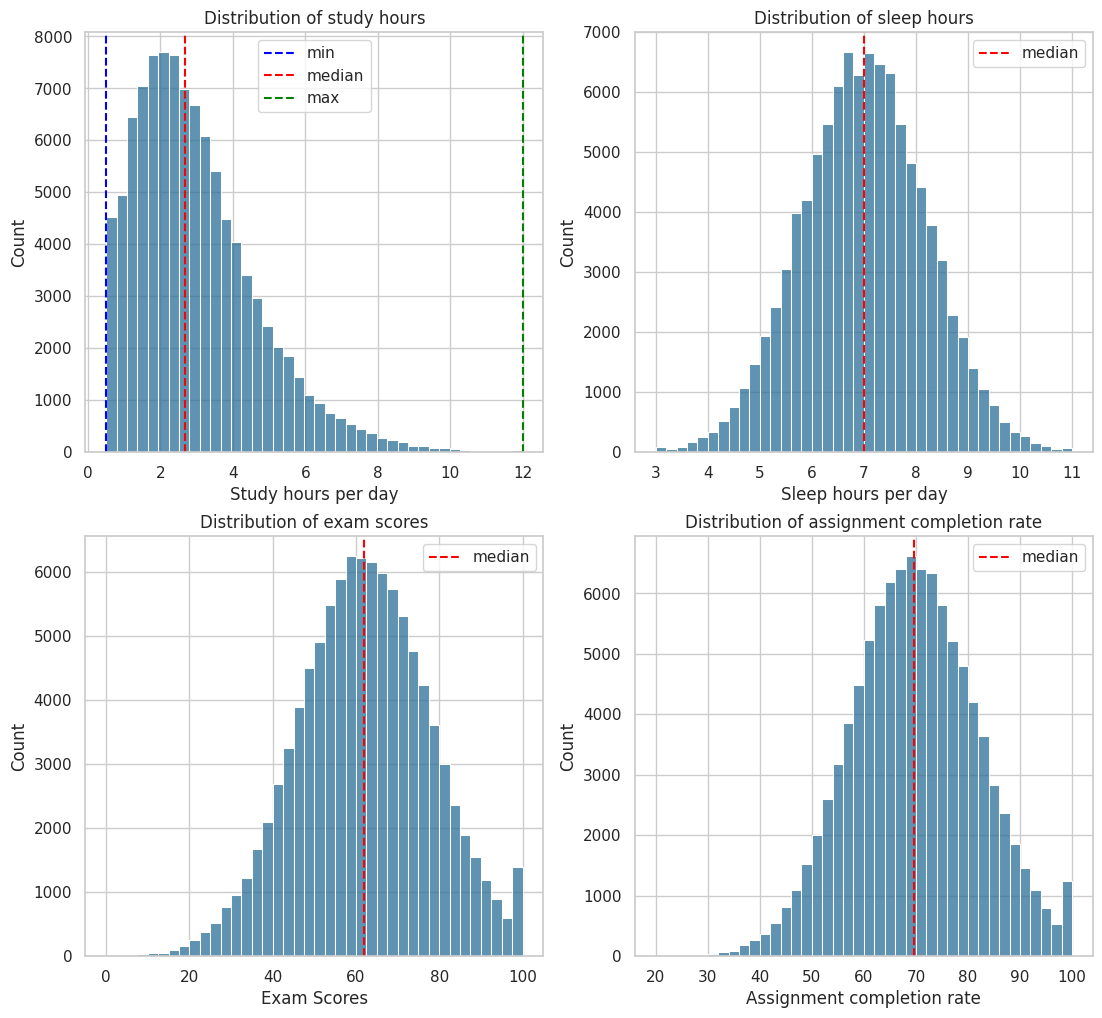

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
cap = student_data["study_hours_per_day"].quantile(1)
sns.histplot(student_data["study_hours_per_day"].clip(upper=cap), bins=40, ax=axes[0, 0], color="#2a6f97")
axes[0, 0].axvline(df["study_hours_per_day"].min(), color="blue", ls="--", label="min")
axes[0, 0].axvline(df["study_hours_per_day"].median(), color="red", ls="--", label="median")
axes[0, 0].axvline(df["study_hours_per_day"].max(), color="green", ls="--", label="max")
axes[0, 0].set(title="Distribution of study hours", xlabel="Study hours per day")
axes[0, 0].legend()

cap = student_data["sleep_hours"].quantile(1)
sns.histplot(student_data["sleep_hours"].clip(upper=cap), bins=40, ax=axes[0, 1], color="#2a6f97")
axes[0, 1].axvline(df["sleep_hours"].median(), color="red", ls="--", label="median")
axes[0, 1].set(title="Distribution of sleep hours", xlabel="Sleep hours per day")
axes[0, 1].legend()

cap = student_data["exam_score"].quantile(1)
sns.histplot(student_data["exam_score"].clip(upper=cap), bins=40, ax=axes[1, 0], color="#2a6f97")
axes[1, 0].axvline(df["exam_score"].median(), color="red", ls="--", label="median")
axes[1, 0].set(title="Distribution of exam scores", xlabel="Exam Scores")
axes[1, 0].legend()

cap = student_data["assignment_completion_rate"].quantile(1)
sns.histplot(student_data["assignment_completion_rate"].clip(upper=cap), bins=40, ax=axes[1, 1], color="#2a6f97")
axes[1, 1].axvline(df["assignment_completion_rate"].median(), color="red", ls="--", label="median")
axes[1, 1].set(title="Distribution of assignment completion rate", xlabel="Assignment completion rate")
axes[1, 1].legend()

##Question 1: Which students are overworking without payoff, and what’s the relationship between effort and outcome?

Overworking in this context means high assignment completion rate and high study hours per day

In [ ]:
hi_effort = student_data["study_hours_per_day"].quantile(0.75)
lo_score  = student_data["exam_score"].quantile(0.25)

student_data["overworked_no_payoff"] = (
    (student_data["study_hours_per_day"] >= hi_effort) &
    (student_data["exam_score"] <= lo_score)
)
print(student_data["overworked_no_payoff"].mean() * 100, "% of students")

2.817 % of students


Text(0.5, 1.0, 'Effort vs. score: students working hard without payoff')

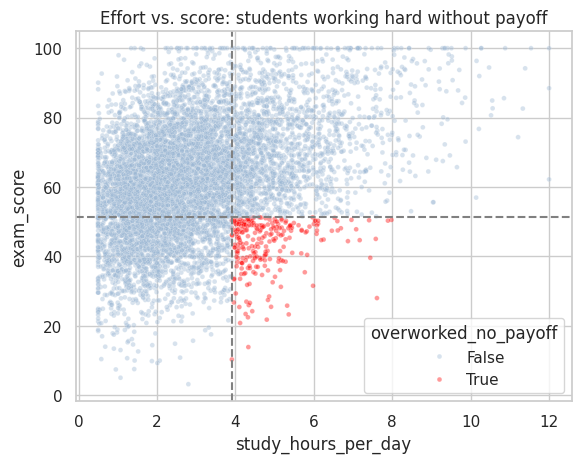

In [ ]:
sample = student_data.sample(8000, random_state=1)
sns.scatterplot(data=sample, x="study_hours_per_day", y="exam_score",
                hue="overworked_no_payoff", palette={False: "#9bb7d4", True: "red"}, alpha=0.4, s=12)
plt.axvline(hi_effort, ls="--", color="gray"); plt.axhline(lo_score, ls="--", color="gray")
plt.title("Effort vs. score: students working hard without payoff")

In [ ]:
profile = student_data.groupby("overworked_no_payoff").agg(
    students=("student_id", "count"),
    avg_study_hours=("study_hours_per_day", "mean"),
    avg_sleep=("sleep_hours", "mean"),
    avg_stress=("stress_level", "mean"),
    avg_attendance=("attendance_percentage", "mean"),
    avg_prev_score=("previous_exam_score", "mean"),
    pct_hard_exam=("exam_difficulty", lambda s: (s == "Hard").mean() * 100),
).round(2)
profile

,students,avg_study_hours,avg_sleep,avg_stress,avg_attendance,avg_prev_score,pct_hard_exam
overworked_no_payoff,,,,,,,
False,97183,2.94,7.01,9.37,84.68,69.82,24.30
True,2817,4.90,6.64,9.63,82.31,59.60,48.88


In [ ]:
#@title Effort groups
student_data["effort_group"] = pd.qcut(
    student_data["study_hours_per_day"], 4,
    labels=["Low", "Medium-Low", "Medium-High", "High"])

effort_summary = (student_data.groupby("effort_group", observed=True)
    .agg(students=("student_id", "count"),
         avg_study_hours=("study_hours_per_day", "mean"),
         median_score=("exam_score", "median"),
         pass_rate=("pass_status", lambda s: (s == "Pass").mean() * 100))
    .round(2))
effort_summary

,students,avg_study_hours,median_score,pass_rate
effort_group,,,,
Low,25056,1.17,55.79,65.00
Medium-Low,24972,2.20,59.38,73.62
Medium-High,25107,3.25,63.27,80.75
High,24865,5.38,70.06,90.27


In [ ]:
#@title Spearman correlation: study hours vs. exam score
#Spearman converts data into ranks
rows = [("All exams", student_data["study_hours_per_day"].corr(student_data["exam_score"], method="spearman"))]
for d in ["Easy", "Medium", "Hard"]:
    sub = student_data[student_data["exam_difficulty"] == d]
    rows.append((d, sub["study_hours_per_day"].corr(sub["exam_score"], method="spearman")))
pd.DataFrame(rows, columns=["Exam difficulty", "Spearman (study hours vs. score)"]).round(3)

,Exam difficulty,Spearman (study hours vs. score)
0,All exams,0.34
1,Easy,0.37
2,Medium,0.36
3,Hard,0.36


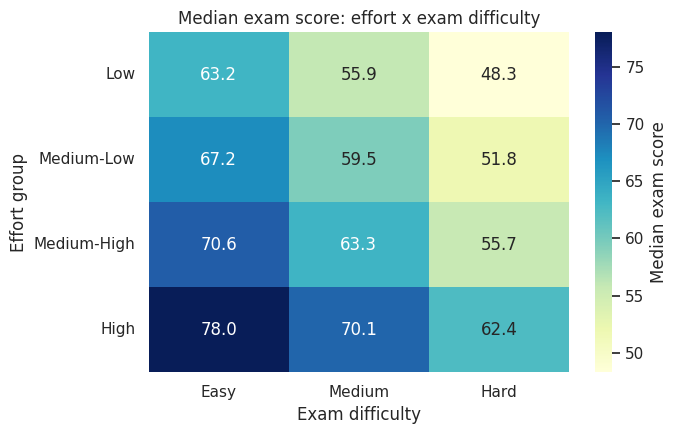

In [ ]:
#@title Heatmap: median score by effort group x exam difficulty - Answers Question 1
q1 = (student_data
      .pivot_table(index="effort_group", columns="exam_difficulty",
                   values="exam_score", aggfunc="median", observed=True)
      [["Easy", "Medium", "Hard"]].round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(q1, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Median exam score"}, ax=ax)
ax.set(title="Median exam score: effort x exam difficulty", xlabel="Exam difficulty", ylabel="Effort group")
plt.tight_layout()
plt.show()

The heatmap shows the relationships between low, medium-low, medium-high, and high effort groups and exam difficulty groups relate to the median exam score. For an easy test, the low effort group can easily pass the exam with a moderate grade. The results change depending on the difficulty and effort.

In [ ]:
#@title High study hours AND high assignment completion, but low score
hi_completion = student_data["assignment_completion_rate"].quantile(0.75)

student_data["overworked_strict"] = (
    (student_data["study_hours_per_day"] >= hi_effort) &
    (student_data["assignment_completion_rate"] >= hi_completion) &
    (student_data["exam_score"] <= lo_score)
)
print(f"Original flag: {student_data['overworked_no_payoff'].sum():,} students "
      f"({student_data['overworked_no_payoff'].mean()*100:.2f}%)")
print(f"Stricter flag: {student_data['overworked_strict'].sum():,} students "
      f"({student_data['overworked_strict'].mean()*100:.2f}%)")

Original flag: 2,817 students (2.82%)
Stricter flag: 1,058 students (1.06%)


In [ ]:
#@title Flagged vs. everyone else (adds score, assignments, and sleep)
profile2 = (student_data.groupby("overworked_no_payoff")
    .agg(students=("student_id", "count"),
         avg_study_hours=("study_hours_per_day", "mean"),
         avg_exam_score=("exam_score", "mean"),
         avg_assignment_completion=("assignment_completion_rate", "mean"),
         avg_sleep_hours=("sleep_hours", "mean"),
         avg_stress=("stress_level", "mean"),
         avg_attendance=("attendance_percentage", "mean"),
         avg_prev_score=("previous_exam_score", "mean"),
         pct_hard_exam=("exam_difficulty", lambda s: (s == "Hard").mean() * 100))
    .round(2).T)
profile2.columns = ["Everyone else", "Overworked, no payoff"]
profile2

,Everyone else,"Overworked, no payoff"
students,"97,183.00","2,817.00"
avg_study_hours,2.94,4.90
avg_exam_score,62.48,43.68
avg_assignment_completion,69.60,74.07
avg_sleep_hours,7.01,6.64
avg_stress,9.37,9.63
avg_attendance,84.68,82.31
avg_prev_score,69.82,59.60
pct_hard_exam,24.30,48.88


In [ ]:
#@title Sleep groups and % flagged by group
student_data["sleep_group"] = pd.cut(
    student_data["sleep_hours"], bins=[0, 6, 8, 24],
    labels=["Short (<6h)", "Normal (6-8h)", "Long (>8h)"], right=False)

for col in ["sleep_group", "education_level", "family_income", "exam_difficulty"]:
    print(f"\n% flagged by {col}:")
    display((student_data.groupby(col, observed=True)["overworked_no_payoff"].mean() * 100).round(1).to_frame("% flagged"))


% flagged by sleep_group:


,% flagged
sleep_group,
Short (<6h),4.10
Normal (6-8h),2.80
Long (>8h),1.70



% flagged by education_level:


,% flagged
education_level,
High School,2.90
Undergraduate,2.80



% flagged by family_income:


,% flagged
family_income,
High,1.80
Low,3.60
Lower-Middle,3.10
Middle,2.70
Upper-Middle,2.10



% flagged by exam_difficulty:


,% flagged
exam_difficulty,
Easy,0.90
Hard,5.50
Medium,2.40


## Question 2: Which student profile is most at risk of failing?

In [ ]:
#@title Overall fail rate and risk columns
student_data["failed"] = (student_data["pass_status"] == "Fail").astype(int)
overall_fail = student_data["failed"].mean() * 100
print(f"Overall fail rate: {overall_fail:.1f}%  ({student_data['failed'].sum():,} of {len(student_data):,} students)")

# Bands for numeric factors (quartiles keep group sizes equal)
student_data["stress_group"] = pd.cut(student_data["stress_level"], bins=[0, 7, 9, 10],
                                      labels=["Lower (<=7)", "High (8-9)", "Max (10)"])
student_data["attendance_group"] = pd.qcut(student_data["attendance_percentage"], 4,
                                           labels=["Lowest 25%", "Low-Mid", "High-Mid", "Highest 25%"])
student_data["prev_score_group"] = pd.qcut(student_data["previous_exam_score"], 4,
                                           labels=["Lowest 25%", "Low-Mid", "High-Mid", "Highest 25%"])
student_data["completion_group"] = pd.qcut(student_data["assignment_completion_rate"], 4,
                                           labels=["Lowest 25%", "Low-Mid", "High-Mid", "Highest 25%"])
student_data["prep_group"] = pd.cut(student_data["exam_preparation_days"], bins=[0, 10, 20, 30],
                                    labels=["1-10 days", "11-20 days", "21-30 days"])
# effort_group and sleep_group were created earlier in the notebook

Overall fail rate: 22.6%  (22,611 of 100,000 students)


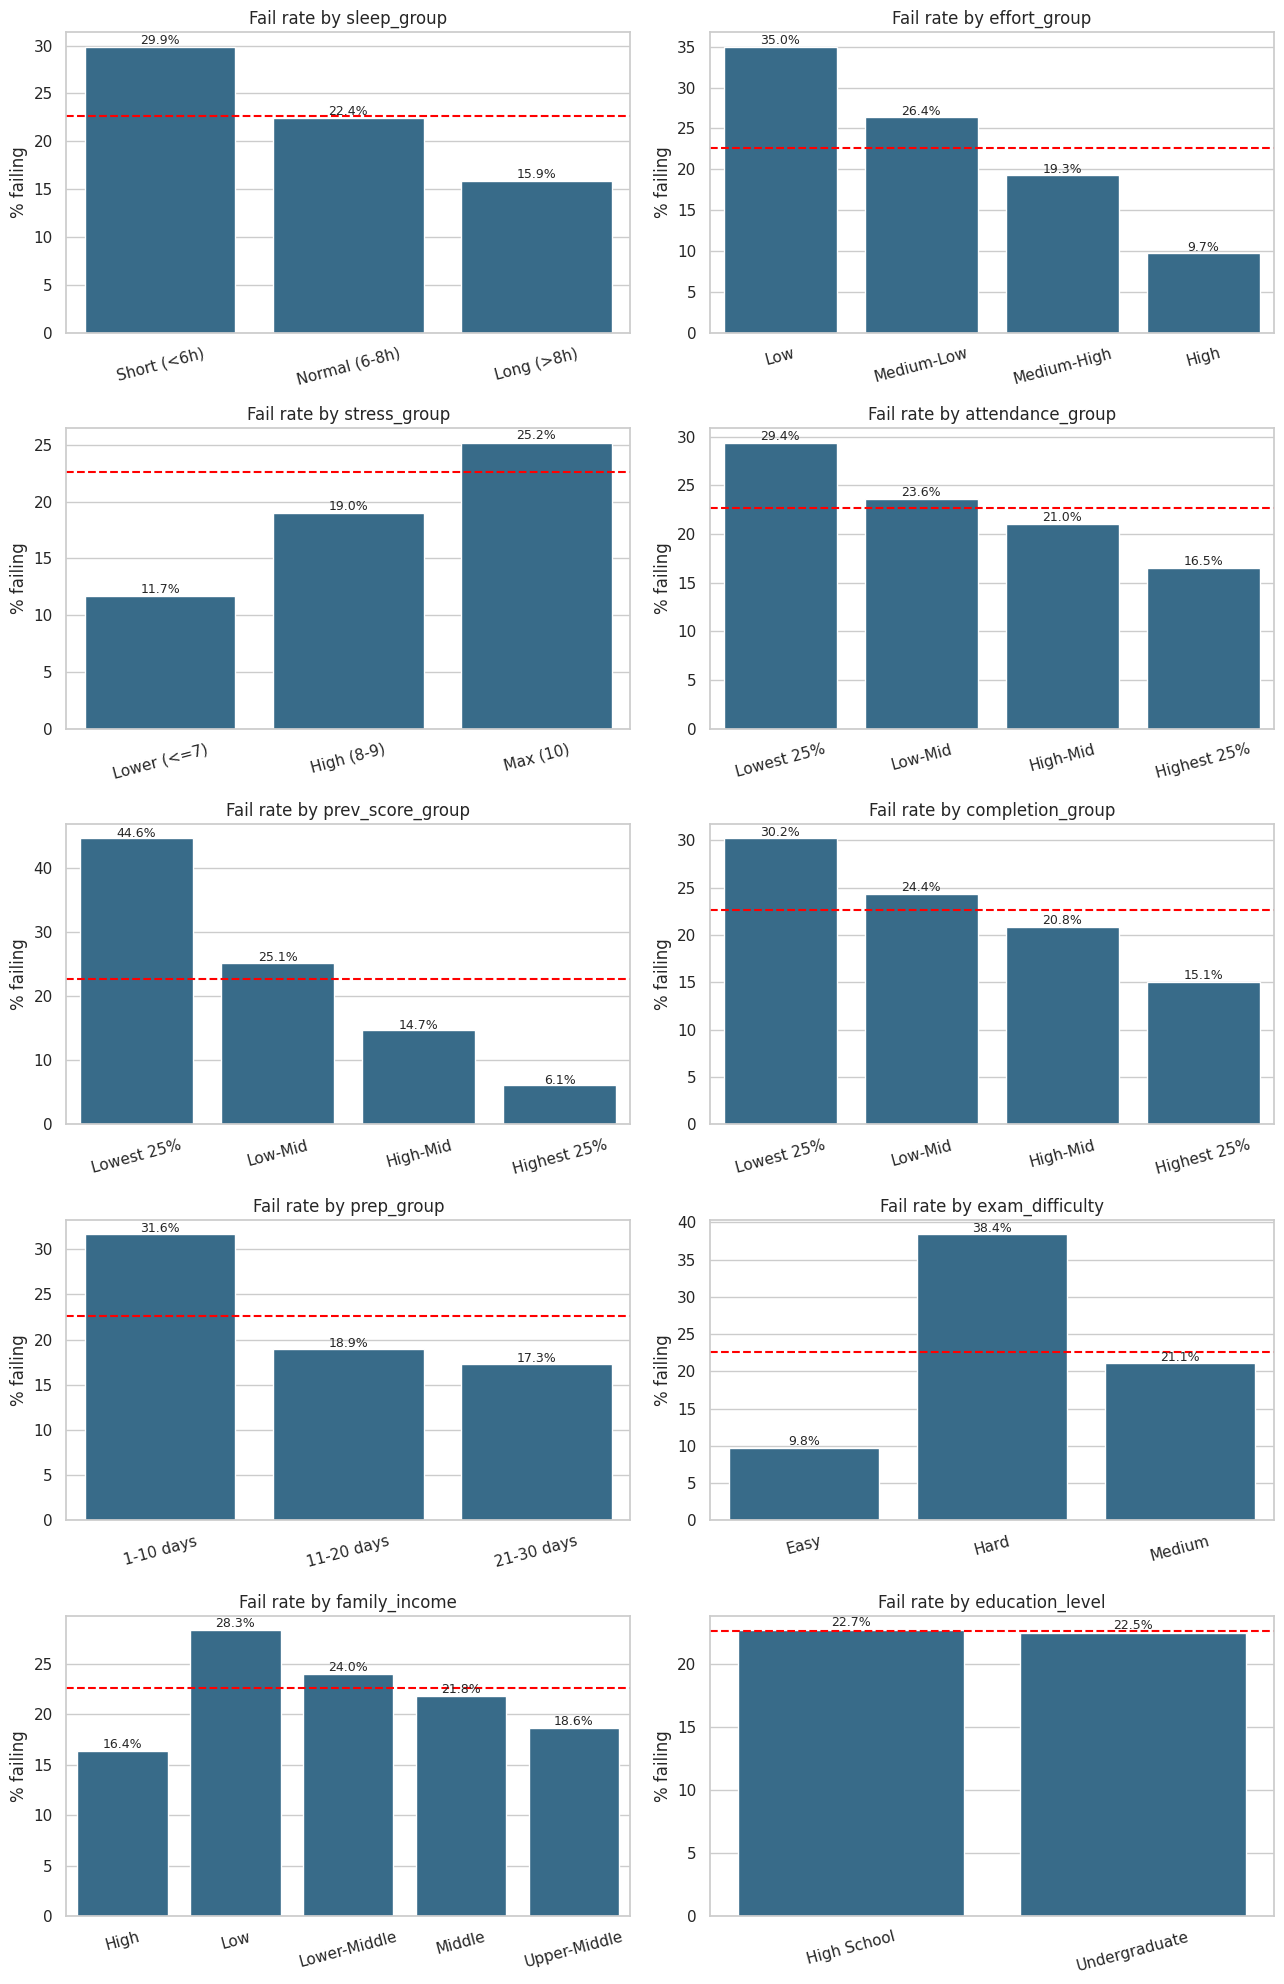

In [ ]:
#@title Fail rate by each factor
factors = ["sleep_group", "effort_group", "stress_group", "attendance_group", "prev_score_group",
           "completion_group", "prep_group", "exam_difficulty", "family_income", "education_level"]

fig, axes = plt.subplots(5, 2, figsize=(13, 20))
for ax, col in zip(axes.ravel(), factors):
    rate = student_data.groupby(col, observed=True)["failed"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#2a6f97", ax=ax)
    ax.axhline(overall_fail, ls="--", color="red")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set(title=f"Fail rate by {col}", xlabel="", ylabel="% failing")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
#@title Which factors separate pass from fail the most?
rows = []
for col in factors:
    g = student_data.groupby(col, observed=True)["failed"].mean() * 100
    rows.append({"factor": col, "lowest_fail_rate": g.min(), "highest_fail_rate": g.max(),
                 "gap_(pts)": g.max() - g.min(), "riskiest_group": str(g.idxmax())})
factor_rank = pd.DataFrame(rows).sort_values("gap_(pts)", ascending=False).round(1).reset_index(drop=True)
factor_rank

,factor,lowest_fail_rate,highest_fail_rate,gap_(pts),riskiest_group
0,prev_score_group,6.10,44.60,38.50,Lowest 25%
1,exam_difficulty,9.80,38.40,28.60,Hard
2,effort_group,9.70,35.00,25.30,Low
3,completion_group,15.10,30.20,15.10,Lowest 25%
4,prep_group,17.30,31.60,14.40,1-10 days
5,sleep_group,15.90,29.90,14.00,Short (<6h)
6,stress_group,11.70,25.20,13.60,Max (10)
7,attendance_group,16.50,29.40,12.90,Lowest 25%
8,family_income,16.40,28.30,11.90,Low
9,education_level,22.50,22.70,0.20,High School


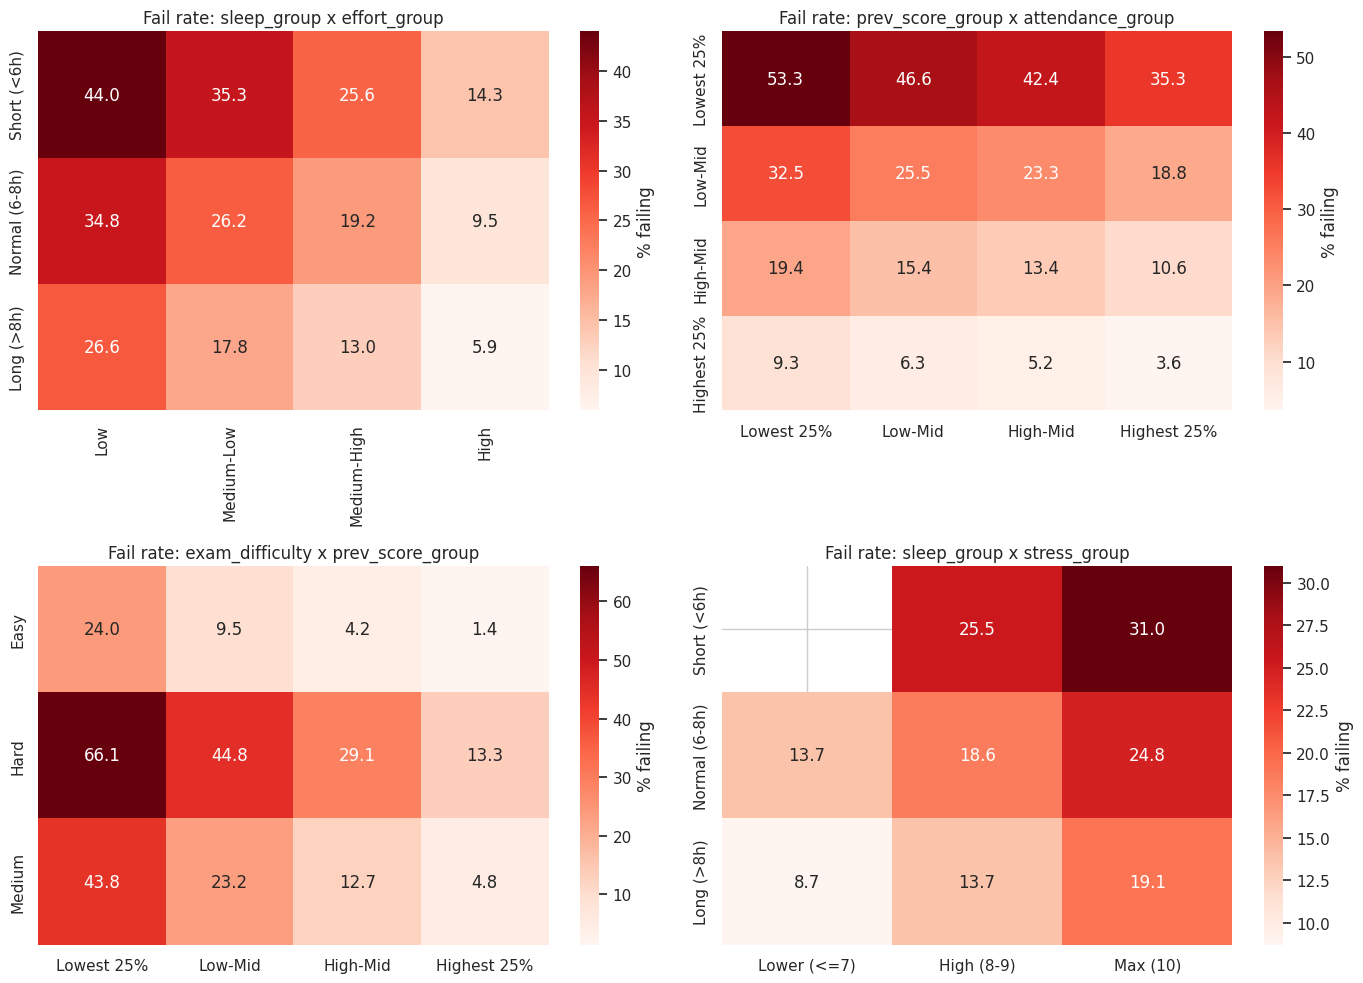

In [ ]:
#@title Heatmaps: Fail rate for pairs of factors
pairs = [("sleep_group", "effort_group"),
         ("prev_score_group", "attendance_group"),
         ("exam_difficulty", "prev_score_group"),
         ("sleep_group", "stress_group")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (r, c) in zip(axes.ravel(), pairs):
    tbl = (student_data.pivot_table(index=r, columns=c, values="failed", aggfunc="mean", observed=True) * 100).round(1)
    sns.heatmap(tbl, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% failing"}, ax=ax)
    ax.set(title=f"Fail rate: {r} x {c}", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

In [ ]:
#@title Top risky profiles
profile_factors = ["sleep_group", "effort_group", "prev_score_group", "exam_difficulty"]   # edit using your factor ranking
MIN_STUDENTS = 200

profiles = (student_data.groupby(profile_factors, observed=True)
            .agg(students=("student_id", "count"), fail_rate=("failed", lambda s: s.mean() * 100))
            .reset_index())
profiles = profiles[profiles["students"] >= MIN_STUDENTS].copy()
profiles["lift"] = profiles["fail_rate"] / overall_fail
profiles = profiles.sort_values("fail_rate", ascending=False).round(2)

print(f"Profiles with at least {MIN_STUDENTS} students: {len(profiles)}")
print("\nMOST at-risk profiles:")
display(profiles.head(10).reset_index(drop=True))
print("\nLEAST at-risk profiles:")
display(profiles.tail(5).reset_index(drop=True))

Profiles with at least 200 students: 144

MOST at-risk profiles:


,sleep_group,effort_group,prev_score_group,exam_difficulty,students,fail_rate,lift
0,Short (<6h),Low,Lowest 25%,Hard,350,92.57,4.09
1,Short (<6h),Medium-Low,Lowest 25%,Hard,330,85.45,3.78
2,Normal (6-8h),Low,Lowest 25%,Hard,932,82.51,3.65
3,Short (<6h),Low,Low-Mid,Hard,333,75.38,3.33
4,Long (>8h),Low,Lowest 25%,Hard,335,75.22,3.33
5,Normal (6-8h),Medium-Low,Lowest 25%,Hard,946,74.84,3.31
6,Short (<6h),Low,Lowest 25%,Medium,653,73.81,3.26
7,Short (<6h),Medium-High,Lowest 25%,Hard,299,73.24,3.24
8,Normal (6-8h),Medium-High,Lowest 25%,Hard,886,66.93,2.96
9,Short (<6h),Medium-Low,Low-Mid,Hard,298,66.44,2.94



LEAST at-risk profiles:


,sleep_group,effort_group,prev_score_group,exam_difficulty,students,fail_rate,lift
0,Long (>8h),High,High-Mid,Easy,286,0.35,0.02
1,Short (<6h),High,Highest 25%,Easy,299,0.33,0.01
2,Normal (6-8h),High,Highest 25%,Easy,865,0.12,0.01
3,Long (>8h),Medium-High,Highest 25%,Easy,306,0.00,0.00
4,Long (>8h),High,Highest 25%,Easy,336,0.00,0.00


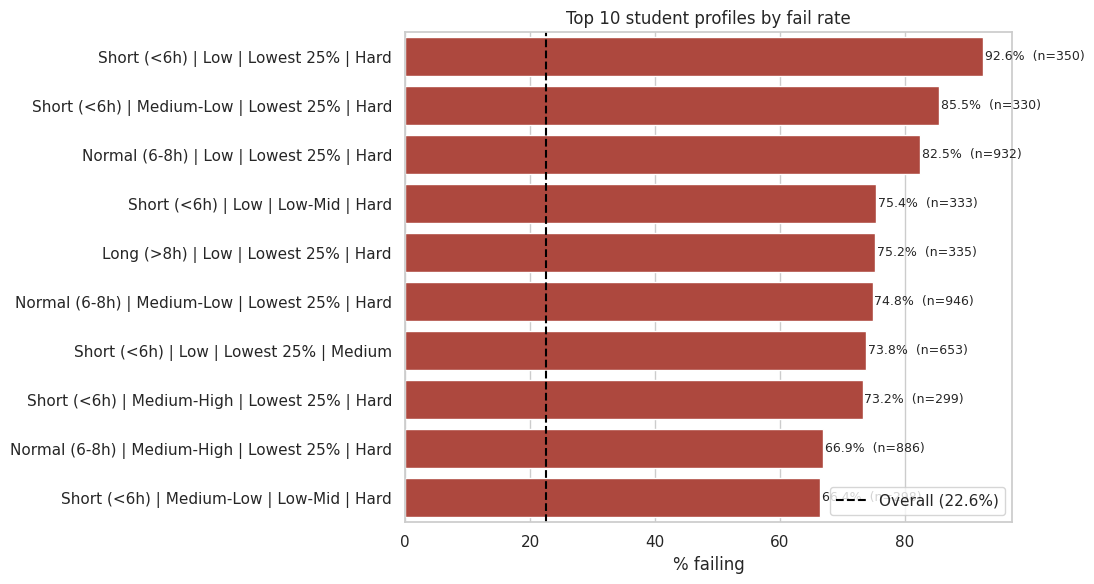

In [ ]:
#@title Top 10 riskiest profiles - Answers Question 2
top = profiles.head(10).copy()
top["label"] = top[profile_factors].astype(str).agg(" | ".join, axis=1)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top, y="label", x="fail_rate", color="#c0392b", ax=ax)
ax.axvline(overall_fail, ls="--", color="black", label=f"Overall ({overall_fail:.1f}%)")
for i, (v, n) in enumerate(zip(top["fail_rate"], top["students"])):
    ax.text(v + 0.3, i, f"{v:.1f}%  (n={n:,})", va="center", fontsize=9)
ax.set(title="Top 10 student profiles by fail rate", xlabel="% failing", ylabel="")
ax.legend()
plt.tight_layout()
plt.show()

The graph shows which combinations of factors from students make them more at-risk. For example, the highest risk group sleep less, provide low effort, were in the lowest 25% of the previous exam, and took a difficult exam.

##Question 3: Does sleep matter as much as study time?

In [ ]:
#@title Does sleep matter as much as study time?
for col in ["study_hours_per_day", "sleep_hours"]:
    r = student_data[col].corr(student_data["exam_score"], method="spearman")
    print(f"{col}: Spearman vs. exam score = {r:.3f}")

# Score gap and fail-rate gap between the best and worst groups
for g in ["effort_group", "sleep_group"]:
    t = student_data.groupby(g, observed=True).agg(median_score=("exam_score", "median"),
                                                   fail_rate=("failed", lambda s: s.mean()*100)).round(1)
    print(f"\n{g}"); display(t)

study_hours_per_day: Spearman vs. exam score = 0.341
sleep_hours: Spearman vs. exam score = 0.163

effort_group


,median_score,fail_rate
effort_group,,
Low,55.80,35.00
Medium-Low,59.40,26.40
Medium-High,63.30,19.30
High,70.10,9.70



sleep_group


,median_score,fail_rate
sleep_group,,
Short (<6h),58.30,29.90
Normal (6-8h),61.90,22.40
Long (>8h),66.00,15.90


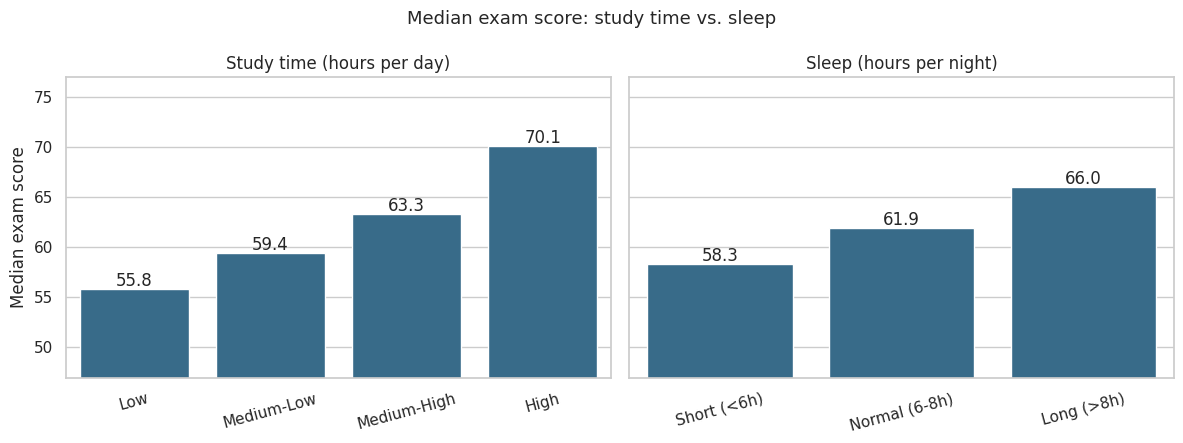

In [ ]:
#@title Median exam score: Study time vs. Sleep - Answers Question 3
#Answers Question 3
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, col, title in [(axes[0], "effort_group", "Study time (hours per day)"),
                       (axes[1], "sleep_group", "Sleep (hours per night)")]:
    med = student_data.groupby(col, observed=True)["exam_score"].median()
    sns.barplot(x=med.index.astype(str), y=med.values, color="#2a6f97", ax=ax)
    for i, v in enumerate(med.values):
        ax.text(i, v + 0.3, f"{v:.1f}", ha="center")
    ax.set(title=title, xlabel="", ylabel="Median exam score")
    ax.set_ylim(student_data["exam_score"].median() - 15, student_data["exam_score"].median() + 15)
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Median exam score: study time vs. sleep", fontsize=13)
plt.tight_layout()
plt.show()

This graph shows that higher study time contributes more to higher exam scores rather than the number of hours of sleep.

##Dashboard

In [ ]:
dashboard_cols = student_data #columns that will shrink the file size and will be used in the dashboard

dashboard_cols.to_csv(DASHBOARD_FILE, index=False)

import os
size_mb = os.path.getsize(DASHBOARD_FILE) / 1_048_576 #file size in megabytes
print(size_mb, " megabytes")
print()
print(f"Saved {DASHBOARD_FILE}: {dashboard_cols.shape[0]:,} rows x {dashboard_cols.shape[1]} columns, {size_mb:.2f} MB") #saves all rows in columns in dataset
print("Under 25 MB target:", size_mb < 25)

16.599323272705078  megabytes

Saved dashboard_data.csv: 100,000 rows x 25 columns, 16.60 MB
Under 25 MB target: True
